# Non-local means denoising: baseline comparison

Compare the same IAM validation samples with no optional preprocessing and with non-local means denoising. Originals and transcriptions are preserved. This visual demonstration does not establish a CER/WER improvement. Keep the test split reserved for final evaluation.

Install `requirements-preprocessing.txt` into the project environment if needed. L and RGB images are supported; other modes raise an explicit error rather than silently adding another preprocessing technique.

In [25]:
import sys
from pathlib import Path
import json
from importlib.metadata import version
from time import perf_counter

import matplotlib.pyplot as plt

from preprocessing import deskew

# Works when launched from either the project root or notebooks/.
PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src" / "load_dataset" / "iam.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.load_dataset.iam import load_iam_dataset, get_sample
from src.preprocessing import NonLocalMeans, PreprocessingPipeline

In [26]:
# Reuse these pipeline objects across all samples.
# Set enabled=False to bypass denoising without changing the comparison code.
SPLIT = "validation"
SAMPLE_INDICES = (3, 4, 5)
pipelines = {
    "baseline": PreprocessingPipeline(),
    "non_local_means": PreprocessingPipeline((
        NonLocalMeans(enabled=True, h=3.0, h_color=3.0,
                      template_window_size=7, search_window_size=21),
    )),
}
print(json.dumps({name: pipeline.to_config() for name, pipeline in pipelines.items()}, indent=2))

{
  "baseline": {
    "steps": []
  },
  "non_local_means": {
    "steps": [
      {
        "name": "non_local_means",
        "enabled": true,
        "h": 3.0,
        "h_color": 3.0,
        "template_window_size": 7,
        "search_window_size": 21
      }
    ]
  }
}


In [27]:
dataset = load_iam_dataset(split=SPLIT)
samples = [get_sample(dataset, index) for index in SAMPLE_INDICES]
metadata = {
    "dataset": "Teklia/IAM-line",
    "split": SPLIT,
    "sample_indices": list(SAMPLE_INDICES),
    "dataset_fingerprint": dataset._fingerprint,
    "dataset_revision": "not pinned by the existing loader",
    "versions": {name: version(name) for name in (
        "numpy", "Pillow", "opencv-python-headless", "datasets", "matplotlib"
    )},
    "preprocessing": {name: pipeline.to_config() for name, pipeline in pipelines.items()},
}
print(json.dumps(metadata, indent=2))
print("Samples in split:", len(dataset))
print("Columns:", dataset.column_names)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


{
  "dataset": "Teklia/IAM-line",
  "split": "validation",
  "sample_indices": [
    3,
    4,
    5
  ],
  "dataset_fingerprint": "996be2943a84a1cf",
  "dataset_revision": "not pinned by the existing loader",
  "versions": {
    "numpy": "2.5.4",
    "Pillow": "13.0.0",
    "opencv-python-headless": "4.14.0.94",
    "datasets": "5.1.0",
    "matplotlib": "3.11.2"
  },
  "preprocessing": {
    "baseline": {
      "steps": []
    },
    "non_local_means": {
      "steps": [
        {
          "name": "non_local_means",
          "enabled": true,
          "h": 3.0,
          "h_color": 3.0,
          "template_window_size": 7,
          "search_window_size": 21
        }
      ]
    }
  }
}
Samples in split: 976
Columns: ['image', 'text']


validation/sample_3: with James Maxwell making a fine job of the
validation/sample_4: " The Little Key . "
validation/sample_5: first-class performance last night as a


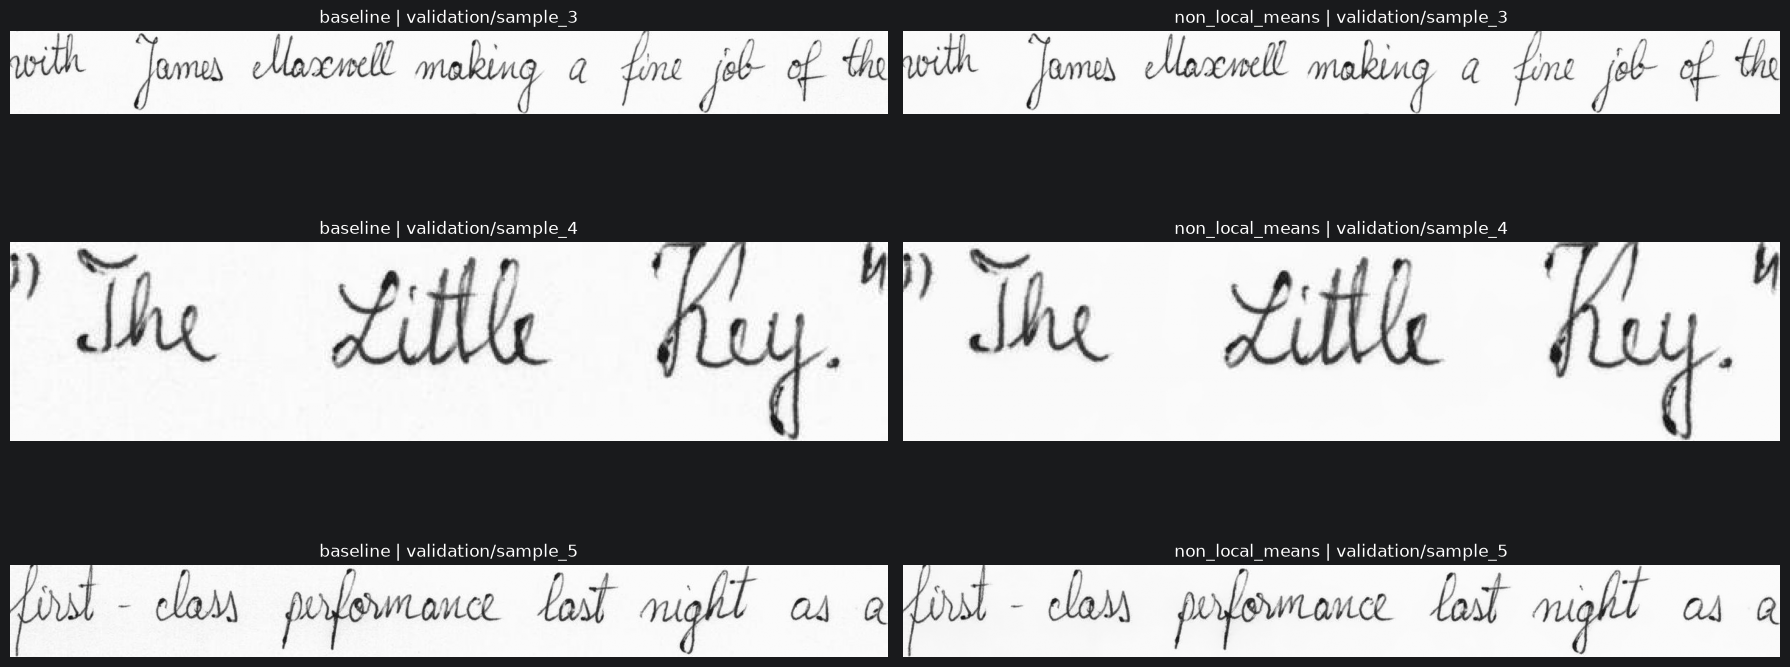

Preprocessing seconds for displayed samples: {'baseline': 0.0002614170080050826, 'non_local_means': 0.15792595798848197}


In [28]:
fig, axes = plt.subplots(
    len(samples), len(pipelines),
    figsize=(18, 3 * len(samples)), squeeze=False,
)
timings = {name: 0.0 for name in pipelines}
for row, sample in enumerate(samples):
    print(f"{SPLIT}/{sample['id']}: {sample['ground_truth']}")
    for col, (name, pipeline) in enumerate(pipelines.items()):
        start = perf_counter()
        processed = pipeline(sample["image"])
        timings[name] += perf_counter() - start
        axes[row, col].imshow(processed, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{name} | {SPLIT}/{sample['id']}")
        axes[row, col].axis("off")
fig.tight_layout()
plt.show()
print("Preprocessing seconds for displayed samples:", timings)

## Using the pipelines in recognition experiments

Pass `pipelines[name](sample["image"])` to the same model wrapper for every configuration. Apply the model's mandatory transforms consistently afterwards. Keep sample indices, transcriptions, checkpoint, decoding settings, and text normalization fixed. Record `metadata` with eventual aggregate CER/WER results.

The strengths (3.0) and window sizes (7 and 21) are initial settings, not tuned research findings. Higher strengths may remove fine strokes. Non-local means can be costly; larger search windows increase work. Compare individual settings on validation data before evaluating combinations or the final test set. Timings above include preprocessing only and are illustrative, not an inference benchmark.